# NYC Yellow Taxi — January 2024 · Interactive

Interactive rebuild of `taxi_analysis.ipynb`. Same corrected SQL against `~/demo_taxi.duckdb` (read-only), but every chart is built with **Altair → Vega-Lite v5**, so all interactivity runs **in the browser** and is fully self-contained in each chart's output (renders on a cold open — no re-run, no widget state).

**How to drive the charts**
- **Hover** any mark for a tooltip with exact values.
- **§1 — drag a box** on the small overview strip to zoom the detail chart (mouse-drag brush, not scroll-wheel — reliable inside JupyterLab).
- **§2 — click** a bar to select an hour; the selection is **linked** to the weekday×hour heatmap (click again to clear).
- **Dropdowns / sliders** rendered above a chart switch the metric, side, view, or date window. These are Vega-Lite *bound parameters*: the variants are pre-aggregated in SQL and filtered live (zero round-trips).

> Note: the notebook pins the renderer to `alt.renderers.enable("mimetype")` and guards the Altair major version at the top of the setup cell, because JupyterLab's built-in viewer only renders Vega-Lite **≤ v5** — an Altair 6 (vega-lite v6) chart shows up blank.

**Data guards carried over from the fixed analysis:** ~2.96M trips, essentially all January 2024 (only 4 stray non-January days). Time aggregates use the half-open window `>= '2024-01-01' AND < '2024-02-01'`; money/distance aggregates also require `total_amount > 0` and `trip_distance BETWEEN 0 AND 60` (the raw column contains a 312,000-mile data error), and durations use second-granularity diffs.

Altair 5.5.0 -> renderer emits application/vnd.vegalite.v5+json


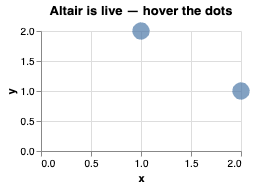

In [12]:
import sys, os

# The kernel may have imported Altair 6 (Vega-Lite v6) before we pinned v5.
# JupyterLab's built-in viewer only renders Vega-Lite <= v5, so drop any cached
# Altair modules and re-import the installed Altair 5.x below.
if "altair" in sys.modules and sys.modules["altair"].__version__.startswith("6"):
    for _m in [k for k in list(sys.modules) if k == "altair" or k.startswith("altair.")]:
        del sys.modules[_m]

import duckdb
import pandas as pd
import altair as alt

assert alt.__version__.startswith("5"), f"need Altair 5.x, got {alt.__version__}"

# Read-only connection: the demo DB must never be mutated by analysis code.
con = duckdb.connect(os.path.expanduser("~/demo_taxi.duckdb"), read_only=True)

# Half-open January window; shared guards for money/distance aggregates.
JAN   = "tpep_pickup_datetime >= '2024-01-01' AND tpep_pickup_datetime < '2024-02-01'"
CLEAN = f"{JAN} AND total_amount > 0 AND trip_distance BETWEEN 0 AND 60"

def q(sql):
    """Run read-only SQL, return a pandas DataFrame."""
    return con.sql(sql).df()

# Render as a native Vega-Lite v5 mimebundle (application/vnd.vegalite.v5+json)
# so JupyterLab draws the charts with its built-in vega viewer. The Altair
# default renderer emits text/html (a <script> JupyterLab won't execute) -> blank.
alt.renderers.enable("mimetype")
alt.data_transformers.disable_max_rows()   # our aggregates are small, but be safe

@alt.theme.register("taxi", enable=True)   # one consistent look for every chart
def _taxi_theme():
    return alt.theme.ThemeConfig({
        "view":  {"stroke": None, "continuousWidth": 450},
        "axis":  {"grid": True, "gridColor": "#eeeeee"},
        "range": {"category": ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]},
    })

def with_zoom(chart):
    """Give an Altair chart scroll/drag zoom + pan."""
    return chart.add_params(alt.selection_interval(bind="scales", name="zoom"))

# All interactivity is Vega-Lite (in-browser): hover tooltips, drag-zoom, click
# selection, and bound dropdown/slider params -- self-contained in each output.

# If you can hover this point and see a tooltip, Altair is rendering live.
print("Altair", alt.__version__, "-> renderer emits", "application/vnd.vegalite.v5+json")
alt.Chart(pd.DataFrame({"x": [1, 2], "y": [2, 1]})).mark_circle(size=300).encode(
    x="x:Q", y="y:Q", tooltip=["x:Q", "y:Q"]
).properties(height=120, width=200, title="Altair is live — hover the dots")

## 1. Daily volume — drag to zoom, hover to read

~2.96M trips, effectively all in January 2024. **Drag a box across the small overview strip** and the detail chart below zooms to that date range; hover the line for exact counts. The mid-month peak (Sat Jan 27) and the New Year's hangover (Jan 2, the 2nd-quietest day) are easy to inspect up close.

In [13]:
daily = q(f"""
    SELECT date_trunc('day', tpep_pickup_datetime)::DATE AS day, count(*) AS trips
    FROM trips WHERE {JAN} GROUP BY 1 ORDER BY 1
""")
# Mouse-drag brush-zoom (works inside JupyterLab, unlike wheel zoom):
# drag a box on the small overview and the detail chart zooms to that range.
brush = alt.selection_interval(encodings=["x"], name="brush")
overview = (
    alt.Chart(daily).mark_area(color="#1f77b422", line={"color": "#1f77b4"})
    .encode(x=alt.X("day:T", axis=alt.Axis(labels=False, title=None)), y="trips:Q")
    .add_params(brush)
    .properties(height=90, title="Overview — drag a box to zoom the chart below")
)
detail = (
    alt.Chart(daily).transform_filter(brush)
    .mark_line(point=True, color="#1f77b4")
    .encode(
        x=alt.X("day:T", title="date"), y=alt.Y("trips:Q", title="trips / day"),
        tooltip=[alt.Tooltip("day:T", title="date"), alt.Tooltip("trips:Q", title="trips", format=",")],
    )
    .properties(height=260, title="Daily pickups — January 2024 (hover for values)")
)
overview & detail

<VegaLite 5 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/display_frontends.html#troubleshooting


## 2. Busiest hour — click a bar to drive the heatmap

The hourly bars (left) and the weekday×hour heatmap (right) share **one** selection. **Click an hour** in the bar chart and the matching column in the heatmap brightens while the rest dim (click again to clear). **6 pm** is the busiest hour; the heatmap shows the Tue–Thu evening ridge and quiet Sunday evenings.

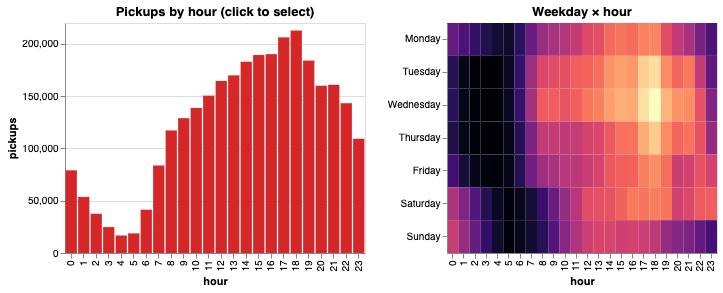

In [14]:
hourly = q(f"""
    SELECT EXTRACT(hour FROM tpep_pickup_datetime)::INT AS hour, count(*) AS pickups
    FROM trips WHERE {JAN} GROUP BY 1 ORDER BY 1
""")
hour_dow = q(f"""
    SELECT EXTRACT(hour FROM tpep_pickup_datetime)::INT AS hour,
           dayname(tpep_pickup_datetime) AS dow, count(*) AS n
    FROM trips WHERE {JAN} GROUP BY 1, 2
""")
ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
hour_dow["dow"] = pd.Categorical(hour_dow["dow"], ORDER)

pick = alt.selection_point(fields=["hour"], name="pick")
bars = (
    alt.Chart(hourly).mark_bar()
    .encode(
        x=alt.X("hour:O", title="hour"), y=alt.Y("pickups:Q", title="pickups"),
        color=alt.condition(pick, alt.value("#d62728"), alt.value("#1f77b4")),
        tooltip=["hour:O", alt.Tooltip("pickups:Q", format=",")],
    )
    .add_params(pick).properties(width=300, height=230, title="Pickups by hour (click to select)")
)
heat = (
    alt.Chart(hour_dow).mark_rect()
    .encode(
        x=alt.X("hour:O", title="hour"),
        y=alt.Y("dow:N", sort=ORDER, title=None),
        color=alt.Color("n:Q", scale=alt.Scale(scheme="magma"), legend=None),
        opacity=alt.condition(pick, alt.value(1), alt.value(0.25)),
        tooltip=["dow:N", "hour:O", alt.Tooltip("n:Q", format=",")],
    )
    .properties(width=270, height=230, title="Weekday × hour")
)
bars | heat

## 3. Top pickup zones — switch the metric, window the dates

The **dropdown** re-ranks the zones by trips, average fare, or average speed (each pre-aggregated in SQL, switched instantly in the browser). Below it, the daily-lines chart of those top-5 zones has **from/to day sliders** to window the range and **hover** for values (Manhattan zones swing on the weekday cycle; JFK is the steadiest at ~±17% daily CV vs ~±29% for Midtown Center).

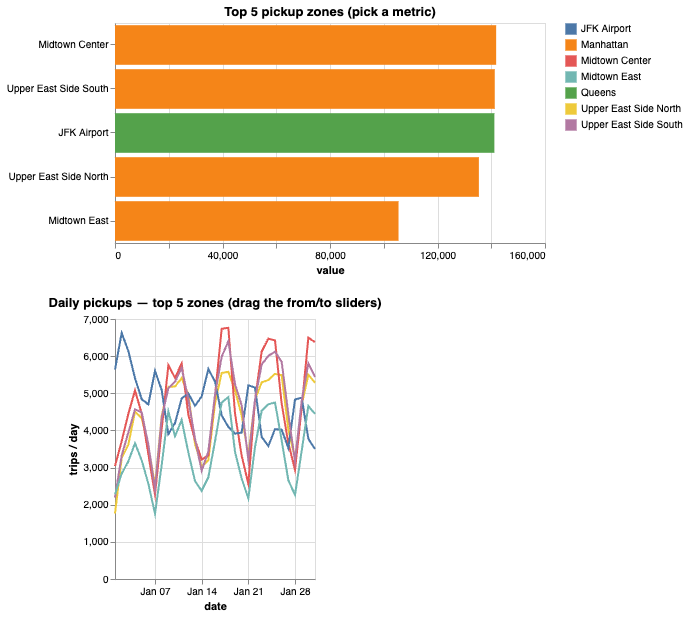

In [15]:
# Precompute the top-5 zones for every metric into one tidy "long" frame; a
# bound dropdown filters to the chosen metric entirely in the browser (no re-query).
AGG = {
    "trips":           "count(*) AS v",
    "avg fare ($)":    "round(avg(total_amount),2) AS v",
    "avg speed (mph)": "round(avg(trip_distance*3600.0/nullif(date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime),0)),1) AS v",
}
zlong = pd.concat([
    q(f"""SELECT z.Borough, z.Zone, {a}
          FROM trips t JOIN zones z ON z.LocationID=t.PULocationID
          WHERE {JAN} AND total_amount>0 GROUP BY 1,2 ORDER BY v DESC LIMIT 5""").assign(metric=m)[["Borough","Zone","v","metric"]]
    for m, a in AGG.items()
], ignore_index=True)

met_p = alt.param(name="met_p", bind=alt.binding_select(options=list(AGG)), value="trips")
rank = (alt.Chart(zlong).add_params(met_p).transform_filter(alt.datum.metric == met_p)
        .mark_bar()
        .encode(x=alt.X("v:Q", title="value"),
                y=alt.Y("Zone:N", sort="-x", title=None),
                color=alt.Color("Borough:N", legend={"title": None}),
                tooltip=["Borough:N", "Zone:N", "metric:N", alt.Tooltip("v:Q")])
        .properties(width=430, height=220, title="Top 5 pickup zones (pick a metric)"))

# Daily volume of the top-5 zones (by trips). Two bound date sliders window it.
zone_daily = q(f"""
    WITH top5 AS (SELECT PULocationID lid FROM trips WHERE {JAN} GROUP BY 1 ORDER BY count(*) DESC LIMIT 5)
    SELECT date_trunc('day', t.tpep_pickup_datetime)::DATE AS day,
           dayofmonth(t.tpep_pickup_datetime) AS di, z.Zone, count(*) AS n
    FROM trips t JOIN zones z ON z.LocationID=t.PULocationID
    WHERE {JAN} AND t.PULocationID IN (SELECT lid FROM top5) GROUP BY 1, 2, 3
""")
from_p = alt.param(name="from_p", bind=alt.binding_range(min=1, max=31, step=1, name="from day"), value=1)
to_p   = alt.param(name="to_p",   bind=alt.binding_range(min=1, max=31, step=1, name="to day"),   value=31)
trend = (alt.Chart(zone_daily).add_params(from_p, to_p)
         .transform_filter((alt.datum.di >= from_p) & (alt.datum.di <= to_p)).mark_line()
         .encode(x=alt.X("day:T", title="date"), y=alt.Y("n:Q", title="trips / day"),
                 color=alt.Color("Zone:N", legend={"title": None}),
                 tooltip=["day:T", "Zone:N", alt.Tooltip("n:Q", format=",")])
         .properties(height=260, title="Daily pickups — top 5 zones (drag the from/to sliders)"))
rank & trend

## 4. Borough demand — toggle pickup vs dropoff

Yellow cabs are effectively a Manhattan product. The **dropdown switches between the pickup side and the dropoff side** (both pre-aggregated in SQL, filtered client-side). The x-axis is **logarithmic** — Manhattan's ~2.66M dropoffs are ~18× Queens, the #2 borough, and Staten Island barely registers. Hover any bar for the exact count.

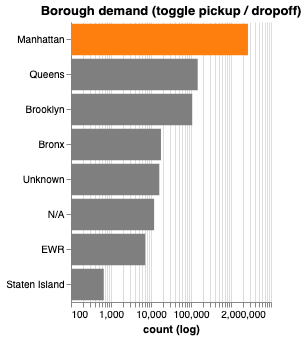

In [16]:
# Both sides precomputed, tagged with a "side" column; a bound dropdown filters
# client-side. Log x-axis because Manhattan is ~18x Queens.
blong = pd.concat([
    q(f"""SELECT z.Borough, count(*) AS n FROM trips t
          JOIN zones z ON z.LocationID=t.{col} WHERE {JAN} GROUP BY 1""").assign(side=side)[["Borough","n","side"]]
    for side, col in [("dropoff", "DOLocationID"), ("pickup", "PULocationID")]
], ignore_index=True)

side_p = alt.param(name="side_p", bind=alt.binding_select(options=["dropoff", "pickup"]), value="dropoff")
(alt.Chart(blong).add_params(side_p).transform_filter(alt.datum.side == side_p)
 .mark_bar()
 .encode(x=alt.X("n:Q", scale=alt.Scale(type="log"), title="count (log)"),
         y=alt.Y("Borough:N", sort="-x", title=None),
         color=alt.condition(alt.datum.Borough == "Manhattan", alt.value("#ff7f0e"), alt.value("#7f7f7f")),
         tooltip=["side:N", "Borough:N", alt.Tooltip("n:Q", format=",")])
 .properties(height=280, title="Borough demand (toggle pickup / dropoff)"))

## 5. JFK → Manhattan — drag the date-range sliders

~71.4k trips at a near-fixed **~$94** average (vs ~$27 citywide): the JFK flat-rate + airport fee keep the fare line flat even as daily volume roughly doubles from weekend to weekday. The two **from/to sliders window the chart by dragging** (hover for exact values). Volume is on the blue bars, average fare on the red line (independent axes).

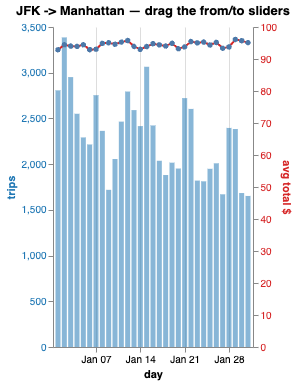

In [17]:
# Daily JFK->Manhattan series with an integer day-of-month "di" so two bound
# range sliders can window the chart by dragging (wheel zoom is unreliable in
# JupyterLab, so sliders are the primary time filter here).
jfk_daily = q(f"""
    SELECT date_trunc('day', t.tpep_pickup_datetime)::DATE AS day,
           dayofmonth(t.tpep_pickup_datetime) AS di,
           count(*) AS trips, round(avg(t.total_amount),2) AS avg_total
    FROM trips t
    JOIN zones pu ON pu.LocationID = t.PULocationID
    JOIN zones d  ON d.LocationID  = t.DOLocationID
    WHERE pu.Zone = 'JFK Airport' AND d.Borough = 'Manhattan' AND {JAN}
      AND t.total_amount > 0 AND t.tpep_dropoff_datetime > t.tpep_pickup_datetime
    GROUP BY 1, 2 ORDER BY 1
""")
start_p = alt.param(name="start_p", bind=alt.binding_range(min=1, max=31, step=1, name="from day"), value=1)
end_p   = alt.param(name="end_p",   bind=alt.binding_range(min=1, max=31, step=1, name="to day"),   value=31)
base = alt.Chart(jfk_daily).add_params(start_p, end_p).transform_filter((alt.datum.di >= start_p) & (alt.datum.di <= end_p))

bars = base.mark_bar(color="#1f77b488").encode(
    x="day:T", y=alt.Y("trips:Q", title="trips", axis={"titleColor": "#1f77b4", "labelColor": "#1f77b4"}),
    tooltip=[alt.Tooltip("day:T"), alt.Tooltip("trips:Q", format=",")])
line = base.mark_line(color="#d62728", point=True).encode(
    x="day:T", y=alt.Y("avg_total:Q", title="avg total $", axis={"titleColor": "#d62728", "labelColor": "#d62728"}),
    tooltip=[alt.Tooltip("avg_total:Q", title="avg total")])
(bars + line).resolve_scale(y="independent").properties(height=320, title="JFK -> Manhattan — drag the from/to sliders")

## 6. Payment & tipping — switch the view

~78% of trips pay by card. **Tips are only recorded on card trips** (`payment_type = 1`), and **medians** are used so a handful of absurd tips can't skew the curve. The **dropdown** switches between the payment-mix donut (hover a slice) and two tip curves (drag-zoom enabled).

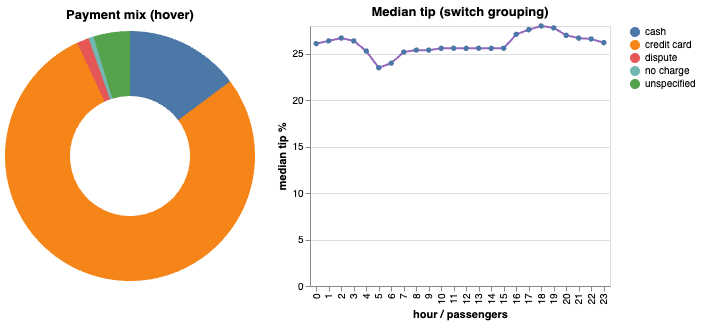

In [18]:
# Payment-mix donut (hover a slice) beside a median-tip line whose grouping
# (hour vs party size) is switched by a bound dropdown over a tidy long frame.
pay = q(f"""SELECT CASE payment_type WHEN 1 THEN 'credit card' WHEN 2 THEN 'cash'
                           WHEN 3 THEN 'no charge' WHEN 4 THEN 'dispute' ELSE 'unspecified' END AS method,
                    count(*) AS trips
             FROM trips WHERE {JAN} GROUP BY 1 ORDER BY trips DESC""")
donut = (alt.Chart(pay).mark_arc(innerRadius=60)
         .encode(theta=alt.Theta("trips:Q"),
                 color=alt.Color("method:N", legend={"title": None}),
                 tooltip=["method:N", alt.Tooltip("trips:Q", format=",")])
         .properties(width=250, height=260, title="Payment mix (hover)"))

tip_long = pd.concat([
    q(f"""SELECT EXTRACT(hour FROM tpep_pickup_datetime)::INT AS g,
                 round(100*median(tip_amount/nullif(fare_amount,0)),1) AS tip
          FROM trips WHERE {JAN} AND payment_type=1 AND fare_amount>0 GROUP BY 1 ORDER BY 1""").assign(grp="tip by hour"),
    q(f"""SELECT passenger_count AS g,
                 round(100*median(tip_amount/nullif(fare_amount,0)),1) AS tip
          FROM trips WHERE {JAN} AND payment_type=1 AND fare_amount>0 AND passenger_count BETWEEN 1 AND 6 GROUP BY 1 ORDER BY 1""").assign(grp="tip by party"),
], ignore_index=True)
grp_p = alt.param(name="grp_p", bind=alt.binding_select(options=["tip by hour", "tip by party"]), value="tip by hour")
tip = (alt.Chart(tip_long).add_params(grp_p).transform_filter(alt.datum.grp == grp_p)
       .mark_line(color="#9467bd", point=True)
       .encode(x=alt.X("g:O", title="hour / passengers"), y=alt.Y("tip:Q", title="median tip %"),
               tooltip=["grp:N", "g:O", "tip:Q"])
       .properties(width=300, height=260, title="Median tip (switch grouping)"))
donut | tip

## 7. Speed by hour — the estimator matters

Two ways to average speed, and they tell different stories. **Distance-weighted** (total miles ÷ total time) shows congestion as a broad ~12 mph daytime plateau; the **unweighted** mean-of-per-trip-speeds exaggerates it into a fake "10 mph floor at 5 pm" because short rush-hour hops count as much as a 15-mile glide. Use the **dropdown** to isolate one estimator, and **hover** for values.

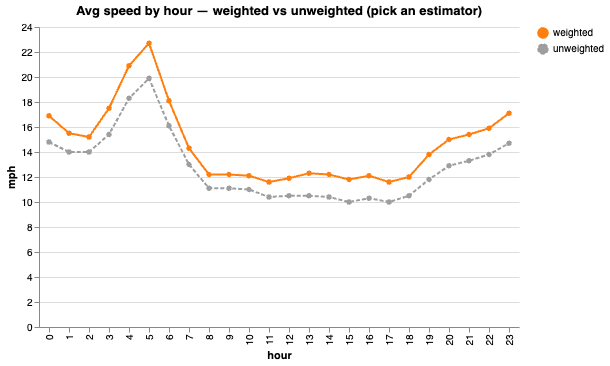

In [19]:
speed = q(f"""
    SELECT EXTRACT(hour FROM tpep_pickup_datetime)::INT AS hour,
           round(sum(trip_distance)*3600.0
                 / nullif(sum(date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime)), 0), 1) AS weighted,
           round(avg(trip_distance*3600.0
                 / nullif(date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime), 0)), 1) AS unweighted
    FROM trips
    WHERE {JAN} AND tpep_dropoff_datetime > tpep_pickup_datetime
      AND date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) BETWEEN 120 AND 7200
      AND trip_distance BETWEEN 0.5 AND 50
    GROUP BY 1 ORDER BY 1
""")
speed_long = speed.melt(id_vars="hour", var_name="estimator", value_name="mph")
# 'both' keeps every estimator; otherwise filter to the one selected.
est_p = alt.param(name="est_p", bind=alt.binding_select(options=["both", "weighted", "unweighted"]), value="both")
(alt.Chart(speed_long).add_params(est_p)
 .transform_filter("datum.estimator === est_p || est_p === 'both'")
 .mark_line(point=True)
 .encode(x=alt.X("hour:O", title="hour", sort=list(range(24))),
         y=alt.Y("mph:Q", title="mph"),
         color=alt.Color("estimator:N", legend={"title": None},
                         scale=alt.Scale(domain=["weighted", "unweighted"], range=["#ff7f0e", "#9e9e9e"])),
         strokeDash=alt.StrokeDash("estimator:N", legend=None,
                                   scale=alt.Scale(domain=["weighted", "unweighted"], range=[[1, 0], [4, 2]])),
         tooltip=["hour:O", "estimator:N", "mph:Q"])
 .properties(height=300, title="Avg speed by hour — weighted vs unweighted (pick an estimator)"))

## 8. JFK flows & top routes — switch the view

The **dropdown** flips between where JFK pickups end and the busiest inter-zone routes citywide. Note the JFK list's #1 "destination" is *JFK Airport itself* (terminal-to-terminal hops); the first real neighbourhood is Times Sq/Theatre District, and the rest is Midtown/Chelsea. Hover any bar.

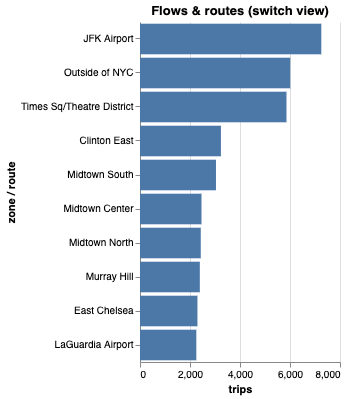

In [20]:
# Both bar-chart views share one encoding (x=trips, y=label), so a bound
# dropdown filters the stacked long frame — no re-query needed.
flows_long = pd.concat([
    q(f"""SELECT d.Zone AS lab, count(*) AS n FROM trips t
          JOIN zones pu ON pu.LocationID=t.PULocationID JOIN zones d ON d.LocationID=t.DOLocationID
          WHERE pu.Zone='JFK Airport' AND {JAN} GROUP BY 1 ORDER BY n DESC LIMIT 10""").assign(view="JFK destinations"),
    q(f"""SELECT pu.Zone || ' -> ' || d.Zone AS lab, count(*) AS n FROM trips t
          JOIN zones pu ON pu.LocationID=t.PULocationID JOIN zones d ON d.LocationID=t.DOLocationID
          WHERE {JAN} AND pu.Zone <> d.Zone GROUP BY 1 ORDER BY n DESC LIMIT 10""").assign(view="Top inter-zone routes"),
], ignore_index=True)
view_p = alt.param(name="view_p", bind=alt.binding_select(options=["JFK destinations", "Top inter-zone routes"]), value="JFK destinations")
(alt.Chart(flows_long).add_params(view_p).transform_filter(alt.datum.view == view_p)
 .mark_bar()
 .encode(x=alt.X("n:Q", title="trips"),
         y=alt.Y("lab:N", sort="-x", title="zone / route"),
         tooltip=["view:N", "lab:N", alt.Tooltip("n:Q", format=",")])
 .properties(height=340, title="Flows & routes (switch view)"))

## 9. New Year's surge — sweep the hour window

At midnight, Jan 1 pulls ~2.7× a typical January night; the gap **widens** to ~7.4× by 3 am (a normal night is nearly over). The **slider** extends the window from hour 1 to 5 to show how far the party runs.

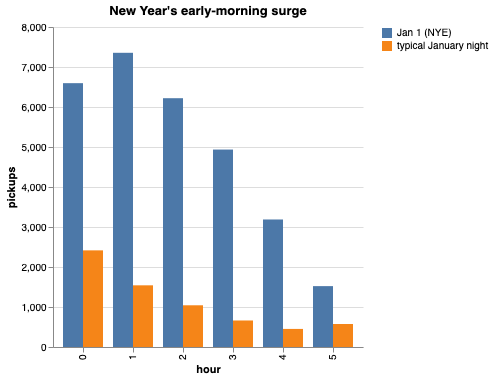

In [21]:
# Jan-1 early hours vs a typical January night; a bound slider widens the window
# from hour 1 to 5 (filtered client-side over both series stacked together).
ny = pd.concat([
    q(f"""SELECT EXTRACT(hour FROM tpep_pickup_datetime)::INT AS hour, round(count(*)/30.0,0) AS v
          FROM trips WHERE tpep_pickup_datetime >= '2024-01-02' AND tpep_pickup_datetime < '2024-02-01'
          GROUP BY 1""").assign(night="typical January night"),
    q("""SELECT EXTRACT(hour FROM tpep_pickup_datetime)::INT AS hour, count(*) AS v
         FROM trips WHERE tpep_pickup_datetime >= '2024-01-01' AND tpep_pickup_datetime < '2024-01-01 06:00'
         GROUP BY 1""").assign(night="Jan 1 (NYE)"),
], ignore_index=True)
hi_p = alt.param(name="hi_p", bind=alt.binding_range(min=1, max=5, step=1, name="show hours 0–"), value=5)
(alt.Chart(ny).add_params(hi_p).transform_filter(alt.datum.hour <= hi_p)
 .mark_bar()
 .encode(x=alt.X("hour:O", title="hour"), y=alt.Y("v:Q", title="pickups"),
         color=alt.Color("night:N", legend={"title": None}), xOffset="night:N",
         tooltip=["hour:O", "night:N", alt.Tooltip("v:Q", format=",.0f")])
 .properties(height=320, title="New Year's early-morning surge"))

## 10. Vendor split — hover both panels

Vendor 2 handles ~75% of trips, but the two networks price and tip almost identically (they're dispatch networks, not competing products). Left: trips by vendor. Right: daily market share. **Hover** any bar or point for exact values.

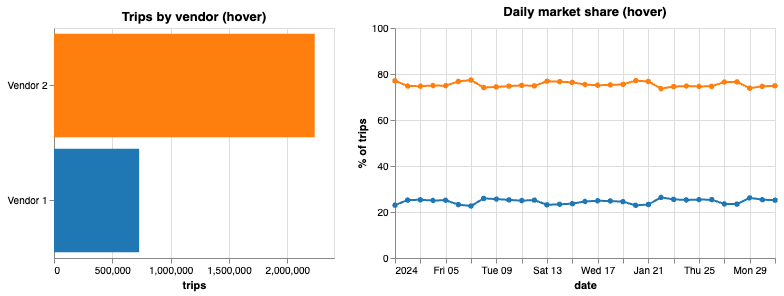

In [22]:
vend = q(f"""SELECT 'Vendor '||VendorID AS vendor, count(*) AS trips,
                    round(avg(total_amount),2) AS avg_total
             FROM trips WHERE {JAN} AND VendorID IN (1,2) GROUP BY 1""")
bar = (alt.Chart(vend).mark_bar()
       .encode(x=alt.X("trips:Q", title="trips"),
               y=alt.Y("vendor:N", sort="-x", title=None),
               color=alt.Color("vendor:N", legend=None, scale=alt.Scale(scheme="category10")),
               tooltip=["vendor:N", alt.Tooltip("trips:Q", format=","), alt.Tooltip("avg_total:Q", title="avg total $")])
       .properties(width=280, height=230, title="Trips by vendor (hover)"))

vd = q(f"""SELECT date_trunc('day', tpep_pickup_datetime)::DATE AS day,
                  'Vendor '||VendorID AS vendor, count(*) AS n
           FROM trips WHERE {JAN} AND VendorID IN (1,2) GROUP BY 1,2""")
vd["pct"] = 100 * vd.n / vd.groupby("day")["n"].transform("sum")
line = (alt.Chart(vd).mark_line(point=True)
        .encode(x=alt.X("day:T", title="date"),
                y=alt.Y("pct:Q", title="% of trips", scale=alt.Scale(domain=[0, 100])),
                color=alt.Color("vendor:N", legend={"title": None}, scale=alt.Scale(scheme="category10")),
                tooltip=["day:T", "vendor:N", alt.Tooltip("pct:Q", title="% share", format=".1f")])
        .properties(width=380, height=230, title="Daily market share (hover)"))
bar | line

## Takeaways (interactive)

Everything the static notebook found, now explorable:

- **~2.96M trips**, effectively all January 2024; mean fare ~$27 (median ~$20), mean distance 3.2 mi on the cleaned guard.
- **6 pm is the busiest pickup hour**; §2's linked selection lets you probe any hour against the weekday heatmap.
- **JFK is the #1 pickup zone** with Manhattan (Midtown/UES) behind it; §3's dropdown swaps the ranking metric live.
- **Manhattan absorbs ~90% of dropoffs**; §4 toggles pickup vs dropoff.
- **JFK → Manhattan** is a premium, near-fixed-price lane (~$94, ~19 mi, ~46 min); §5's sliders re-window it.
- **Card pays ~78%**, median tip ~26% (§6); **congestion is an all-day ~12 mph plateau** (§7), not a single 5 pm spike once weighted properly.
- **New Year's** demand runs 2.7×→7.4× into the pre-dawn hours (§9), and Jan 2 is the 2nd-quietest day.
- **Vendor 2** is ~75% of trips yet the two networks serve almost identically (§10).

All interactivity here is **Vega-Lite in the browser** — hover tooltips, drag-zoom, click/linked selection, and bound dropdown/slider params. Because it lives in the chart spec itself, it needs no running kernel to *be* interactive and no widget state to persist: open the notebook and the charts already respond. (Aggregating variants is done once, in SQL, at the top of each cell.)